In [2]:
import os
import re
import string
import warnings

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix

warnings.filterwarnings("ignore")
# Create an output folder for charts and results
os.makedirs("outputs", exist_ok=True)

# Load dataset

In [ ]:
df = pd.read_csv(
    r"C:\Users\Hp\Desktop\OASIS_INFOBYTE\Email Spam Detection\Data\SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8")

print("\nFIRST FIVE MESSAGES:")
print(df.head())

print("\nDATASET SHAPE:")
print(df.shape)

print("\nCOLUMN INFORMATION:")
print(df.info())

print("\nMISSING VALUES:")
print(df.isnull().sum())


FIRST FIVE MESSAGES:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

DATASET SHAPE:
(5572, 2)

COLUMN INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

MISSING VALUES:
label      0
message    0
dtype: int64


# Data cleaning

In [4]:
# Remove rows with missing labels or messages
df = df.dropna(subset=["label", "message"])

# Remove duplicate messages
print("\nDUPLICATES BEFORE CLEANING:", df.duplicated().sum())
df = df.drop_duplicates()

# Standardise labels and message text
df["label"] = df["label"].str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

# Keep only valid labels
df = df[df["label"].isin(["spam", "ham"])]

print("\nDATASET SHAPE AFTER CLEANING:")
print(df.shape)

print("\nCLASS COUNTS:")
print(df["label"].value_counts())


DUPLICATES BEFORE CLEANING: 403

DATASET SHAPE AFTER CLEANING:
(5169, 2)

CLASS COUNTS:
label
ham     4516
spam     653
Name: count, dtype: int64


# Class distribution

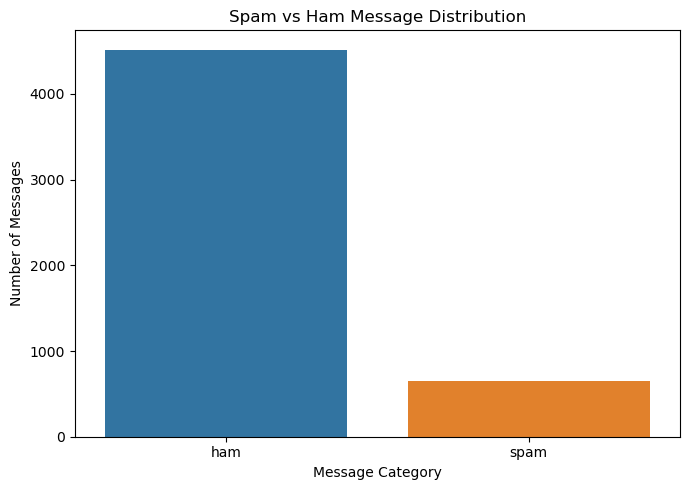

In [5]:
# Count spam and ham messages
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="label",
    hue="label",
    legend=False
)

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.savefig("outputs/class_distribution.png")
plt.show()

In [6]:
# Calculate class percentages
class_percentages = (
    df["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nCLASS PERCENTAGES:")
print(class_percentages)


CLASS PERCENTAGES:
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


# Text preprocessing

In [7]:
# This function cleans each message.
def clean_text(text):

    # Convert all letters to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove numbers
    text = re.sub(r"\d+", " ", text)

    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))

    # Split sentence into individual words
    words = text.split()

    # Remove English stopwords
    # Example: the, is, a, an, and
    words = [word for word in words
        if word not in ENGLISH_STOP_WORDS]

    # Join the cleaned words into a sentence
    return " ".join(words)


# Apply preprocessing to all messages
df["clean_message"] = df["message"].apply(clean_text)

print("\nORIGINAL AND CLEANED MESSAGES:")
print(df[["message", "clean_message"]].head(10))


ORIGINAL AND CLEANED MESSAGES:
                                             message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   
5  FreeMsg Hey there darling it's been 3 week's n...   
6  Even my brother is not like to speak with me. ...   
7  As per your request 'Melle Melle (Oru Minnamin...   
8  WINNER!! As a valued network customer you have...   
9  Had your mobile 11 months or more? U R entitle...   

                                       clean_message  
0  jurong point crazy available bugis n great wor...  
1                            ok lar joking wif u oni  
2  free entry wkly comp win fa cup final tkts st ...  
3                        u dun say early hor u c say  
4                      nah dont think goes usf lives  
5  freemsg hey darlin

# Seperate feature & target

In [8]:
# X contains the message text
X = df["message"]

# y contains the class label
y = df["label"]

print("\nFEATURE EXAMPLE:")
print(X.head())

print("\nTARGET EXAMPLE:")
print(y.head())


FEATURE EXAMPLE:
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: object

TARGET EXAMPLE:
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: object


# Train-Test Split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("\nTRAINING MESSAGES:", len(X_train))
print("TESTING MESSAGES:", len(X_test))


TRAINING MESSAGES: 4135
TESTING MESSAGES: 1034


# Modeling

In [ ]:
# Multinominal Naive Bayes model 
naive_bayes_model = Pipeline(steps=[("tfidf",TfidfVectorizer(preprocessor=clean_text,max_features=5000)),
        ("classifier",MultinomialNB())])


naive_bayes_model

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=5000,
                                 preprocessor=<function clean_text at 0x000002D87E165E40>)),
                ('classifier', MultinomialNB())])

In [ ]:
 # Logistic regression model

logistic_model = Pipeline(steps=[("tfidf",TfidfVectorizer(preprocessor=clean_text,max_features=5000)),
        ("classifier",LogisticRegression(max_iter=1000,class_weight="balanced",random_state=42))])


logistic_model

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=5000,
                                 preprocessor=<function clean_text at 0x000002D87E165E40>)),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

# Train & Evaluate Models


Training Multinomial Naive Bayes...

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       903
        spam       1.00      0.78      0.88       131

    accuracy                           0.97      1034
   macro avg       0.98      0.89      0.93      1034
weighted avg       0.97      0.97      0.97      1034

Accuracy: 0.972
Spam Precision: 1.0
Spam Recall: 0.7786
Spam F1 Score: 0.8755


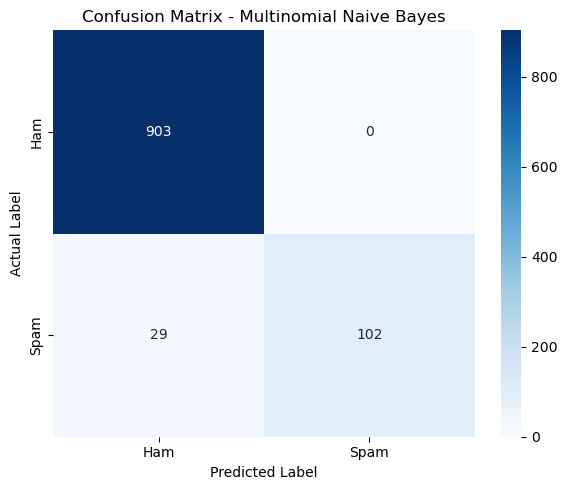


Training Logistic Regression...

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

         ham       0.99      0.98      0.98       903
        spam       0.87      0.91      0.89       131

    accuracy                           0.97      1034
   macro avg       0.93      0.94      0.94      1034
weighted avg       0.97      0.97      0.97      1034

Accuracy: 0.971
Spam Precision: 0.8686
Spam Recall: 0.9084
Spam F1 Score: 0.8881


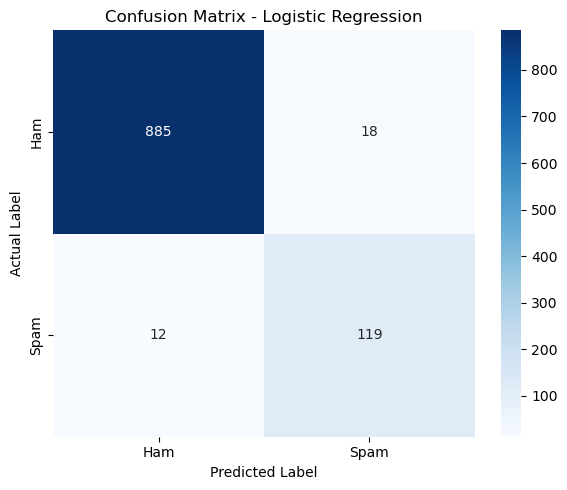

In [13]:
models = {"Multinomial Naive Bayes": naive_bayes_model,"Logistic Regression": logistic_model}

results = []
trained_models = {}

for model_name, model in models.items():

    print(f"\nTraining {model_name}...")

    # Train the model
    model.fit(X_train, y_train)

    # Predict test messages
    predictions = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(y_test,predictions,pos_label="spam",zero_division=0)

    recall = recall_score(y_test,predictions,pos_label="spam",zero_division=0)

    f1 = f1_score(y_test,predictions,pos_label="spam",zero_division=0)

    # Store results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1})

    trained_models[model_name] = model

    print("\nCLASSIFICATION REPORT:")
    print(classification_report(y_test,predictions,zero_division=0))

    print("Accuracy:", round(accuracy, 4))
    print("Spam Precision:", round(precision, 4))
    print("Spam Recall:", round(recall, 4))
    print("Spam F1 Score:", round(f1, 4))

    # Create confusion matrix
    cm = confusion_matrix(y_test,predictions,labels=["ham", "spam"])

    plt.figure(figsize=(6, 5))

    sns.heatmap(cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"])

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()

    filename = (model_name.lower().replace(" ", "_")+ "_confusion_matrix.png")

    plt.savefig(f"outputs/{filename}")
    plt.show()

# Compare models

In [14]:
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON:")
print(results_df.to_string(index=False))

# Choose the model with the highest spam F1 score
best_model_name = results_df.loc[results_df["F1 Score"].idxmax(),"Model"]

best_model = trained_models[best_model_name]

print("\nBEST MODEL:", best_model_name)

# Save comparison results
results_df.to_csv("outputs/model_comparison.csv",index=False)


MODEL COMPARISON:
                  Model  Accuracy  Precision   Recall  F1 Score
Multinomial Naive Bayes  0.971954   1.000000 0.778626  0.875536
    Logistic Regression  0.970986   0.868613 0.908397  0.888060

BEST MODEL: Logistic Regression


# Visualise model performence

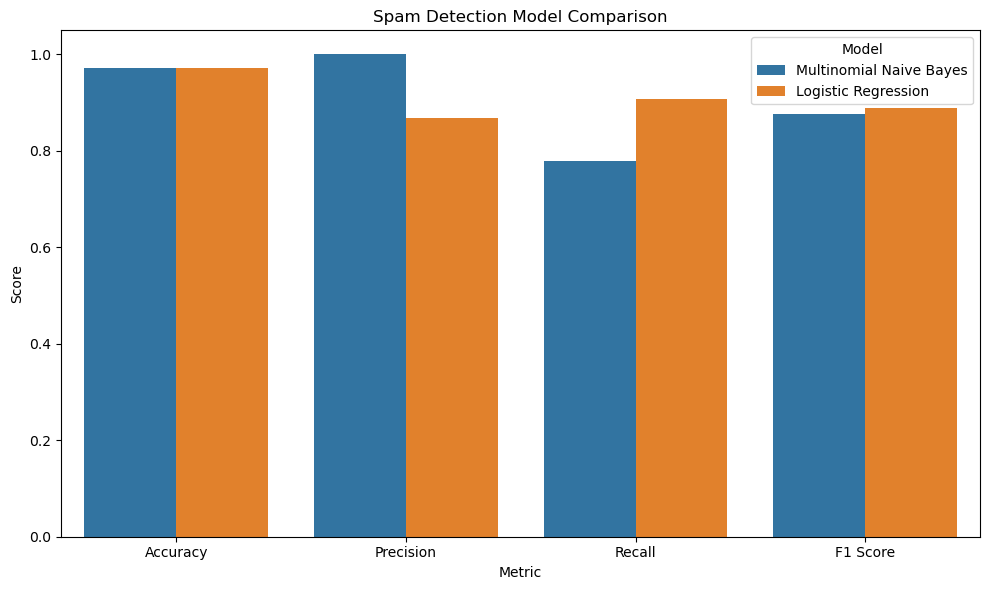

In [15]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"]

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_melted,
    x="Metric",
    y="Score",
    hue="Model")

plt.title("Spam Detection Model Comparison")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.savefig("outputs/model_comparison.png")
plt.show()

# Testing with new messages

In [16]:
test_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hey, are we meeting for lunch today?",
    "URGENT! Claim your cash reward now. Click this link.",
    "I will call you when I reach home."]

print("\nNEW MESSAGE PREDICTIONS:")

for message in test_messages:

    prediction = best_model.predict([message])[0]

    # Get probability of spam
    probabilities = best_model.predict_proba([message])[0]

    spam_index = list(
        best_model.classes_
    ).index("spam")

    spam_probability = probabilities[spam_index] * 100

    print("\nMessage:", message)
    print("Prediction:", prediction.upper())
    print("Spam Probability:",round(spam_probability, 2),"%")


NEW MESSAGE PREDICTIONS:

Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
Spam Probability: 97.33 %

Message: Hey, are we meeting for lunch today?
Prediction: HAM
Spam Probability: 5.33 %

Message: URGENT! Claim your cash reward now. Click this link.
Prediction: SPAM
Spam Probability: 95.71 %

Message: I will call you when I reach home.
Prediction: HAM
Spam Probability: 6.58 %


# Save model

In [17]:
import pickle

with open("spam_detection_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
import pickle

with open("spam_detection_model.pkl", "rb") as file:
    loaded_spam_model = pickle.load(file)

print("Email spam detection model loaded successfully!")